In [1]:
import pandas as pd


In [3]:
df = pd.read_excel(r"C:\Users\Bala murukan\Desktop\PowerBi\Sales Forecasting & Prediction\Retail_Sales_Forecasting_Dataset.xlsx")

In [53]:
df.head()

,OrderID,OrderDate,CustomerID,Category,Region,Product,Sales,Quantity,Profit,Discount
0,ORD000001,2023-01-01,CUST0206,Lifestyle,North,Tablet,826.70,18,68.35,0.229
1,ORD000002,2023-01-02,CUST0544,Lifestyle,North,Laptop,771.96,15,113.29,0.066
2,ORD000003,2023-01-03,CUST0611,Office Supplies,South,Office Chair,845.10,23,148.97,0.226
3,ORD000004,2023-01-04,CUST0906,Lifestyle,West,Storage Drive,926.28,23,167.82,0.080
4,ORD000005,2023-01-05,CUST0387,Furniture,South,Desk,770.53,11,136.35,0.138


In [54]:
df.shape

(1096, 10)

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   OrderID     1096 non-null   object        
 1   OrderDate   1096 non-null   datetime64[ns]
 2   CustomerID  1096 non-null   object        
 3   Category    1096 non-null   object        
 4   Region      1096 non-null   object        
 5   Product     1096 non-null   object        
 6   Sales       1096 non-null   float64       
 7   Quantity    1096 non-null   int64         
 8   Profit      1096 non-null   float64       
 9   Discount    1096 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(5)
memory usage: 85.8+ KB


In [56]:
df.isnull().sum()

OrderID       0
OrderDate     0
CustomerID    0
Category      0
Region        0
Product       0
Sales         0
Quantity      0
Profit        0
Discount      0
dtype: int64

In [57]:
df.duplicated().sum()

0

In [58]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

In [ ]:
df = df.sort_values('OrderDate')
df.head()

In [59]:
monthly_sales = (
    df.groupby(pd.Grouper(key='OrderDate', freq='MS'))['Sales']
    .sum()
    .reset_index()
)

In [60]:
monthly_sales = monthly_sales.rename(
    columns={'Sales': 'MonthlySales'}
)

monthly_sales.head()

,OrderDate,MonthlySales
0,2023-01-01,24777.32
1,2023-02-01,23748.86
2,2023-03-01,29687.80
3,2023-04-01,30018.38
4,2023-05-01,31721.83


In [61]:
monthly_sales['Year'] = monthly_sales['OrderDate'].dt.year
monthly_sales['Month'] = monthly_sales['OrderDate'].dt.month
monthly_sales['Quarter'] = monthly_sales['OrderDate'].dt.quarter

monthly_sales.head()

,OrderDate,MonthlySales,Year,Month,Quarter
0,2023-01-01,24777.32,2023,1,1
1,2023-02-01,23748.86,2023,2,1
2,2023-03-01,29687.80,2023,3,1
3,2023-04-01,30018.38,2023,4,2
4,2023-05-01,31721.83,2023,5,2


In [62]:
monthly_sales['PreviousMonthSales'] = monthly_sales['MonthlySales'].shift(1)

In [63]:
monthly_sales.head()

,OrderDate,MonthlySales,Year,Month,Quarter,PreviousMonthSales
0,2023-01-01,24777.32,2023,1,1,NaN
1,2023-02-01,23748.86,2023,2,1,24777.32
2,2023-03-01,29687.80,2023,3,1,23748.86
3,2023-04-01,30018.38,2023,4,2,29687.80
4,2023-05-01,31721.83,2023,5,2,30018.38


In [64]:
monthly_sales = monthly_sales.dropna().reset_index(drop=True)

In [65]:
monthly_sales.shape

(35, 6)

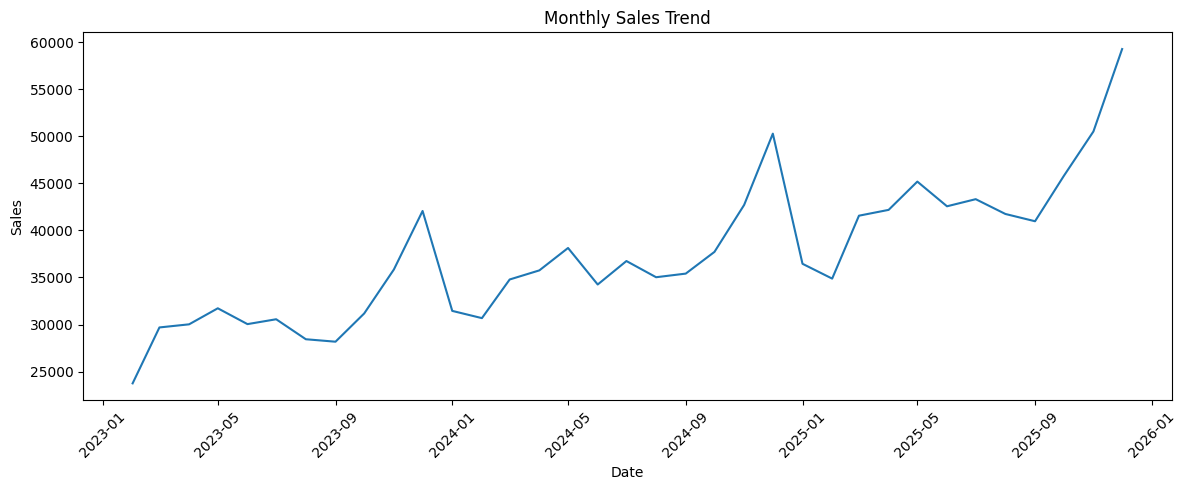

In [66]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales['OrderDate'],
    monthly_sales['MonthlySales']
)

plt.title('Monthly Sales Trend')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [67]:
X = monthly_sales[
    ['Year', 'Month', 'Quarter', 'PreviousMonthSales']
]

y = monthly_sales['MonthlySales']

In [68]:
X.head()

,Year,Month,Quarter,PreviousMonthSales
0,2023,2,1,24777.32
1,2023,3,1,23748.86
2,2023,4,2,29687.80
3,2023,5,2,30018.38
4,2023,6,2,31721.83


In [69]:
split_index = int(len(monthly_sales) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [70]:
print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 28
Testing data: 7


In [71]:
model = LinearRegression()

In [72]:
model.fit(X_train, y_train)

LinearRegression()

In [73]:
y_pred = model.predict(X_test)

In [74]:
results = pd.DataFrame({
    'ActualSales': y_test.values,
    'PredictedSales': y_pred
})

results.head()

,ActualSales,PredictedSales
0,42555.13,44894.299906
1,43310.98,43345.262498
2,41740.04,45423.992187
3,40966.40,46875.600569
4,45769.52,45824.982280


In [75]:
mae = mean_absolute_error(y_test, y_pred)

In [76]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

In [77]:
r2 = r2_score(y_test, y_pred)

In [78]:
print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 2948.3864808010426
RMSE: 3905.9806610152623
R² Score: 0.5860044712903141


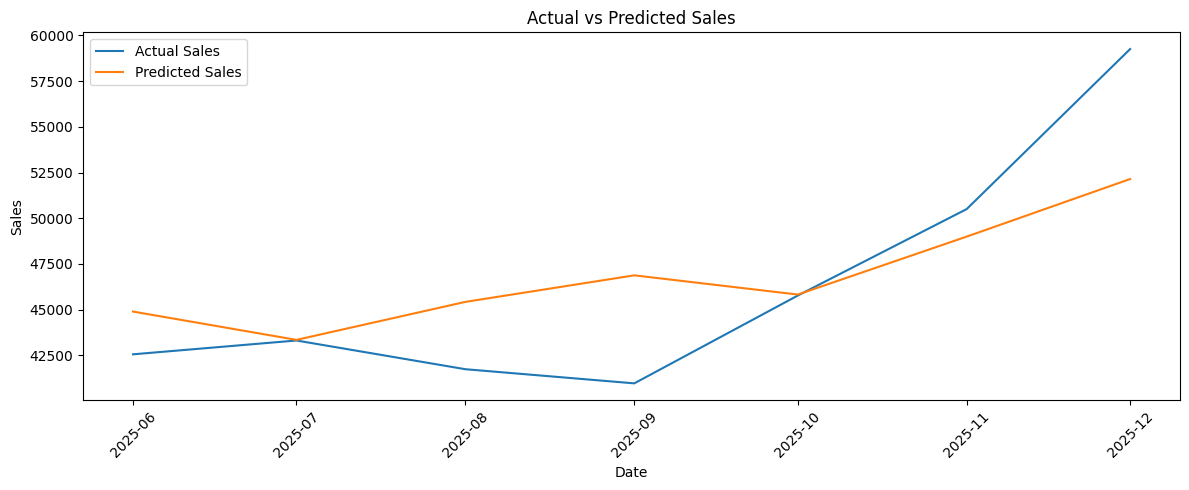

In [79]:
test_dates = monthly_sales['OrderDate'].iloc[split_index:]

plt.figure(figsize=(12, 5))

plt.plot(
    test_dates,
    y_test.values,
    label='Actual Sales'
)

plt.plot(
    test_dates,
    y_pred,
    label='Predicted Sales'
)

plt.title('Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [80]:
last_date = monthly_sales['OrderDate'].max()

future_dates = pd.date_range(
    start=last_date + pd.DateOffset(months=1),
    periods=6,
    freq='MS'
)

future_dates

DatetimeIndex(['2026-01-01', '2026-02-01', '2026-03-01', '2026-04-01',
               '2026-05-01', '2026-06-01'],
              dtype='datetime64[ns]', freq='MS')

In [81]:
future_data = pd.DataFrame({
    'OrderDate': future_dates
})

future_data['Year'] = future_data['OrderDate'].dt.year
future_data['Month'] = future_data['OrderDate'].dt.month
future_data['Quarter'] = future_data['OrderDate'].dt.quarter

In [82]:
previous_sales = monthly_sales['MonthlySales'].iloc[-1]

future_predictions = []

for i in range(len(future_data)):

    features = pd.DataFrame({
        'Year': [future_data.loc[i, 'Year']],
        'Month': [future_data.loc[i, 'Month']],
        'Quarter': [future_data.loc[i, 'Quarter']],
        'PreviousMonthSales': [previous_sales]
    })

    prediction = model.predict(features)[0]

    future_predictions.append(prediction)

    previous_sales = prediction

In [83]:
future_data['PredictedSales'] = future_predictions

future_data

,OrderDate,Year,Month,Quarter,PredictedSales
0,2026-01-01,2026,1,1,46971.121827
1,2026-02-01,2026,2,1,45535.248896
2,2026-03-01,2026,3,1,47023.260837
3,2026-04-01,2026,4,2,46582.207709
4,2026-05-01,2026,5,2,48338.345564
5,2026-06-01,2026,6,2,50686.674928


In [84]:
test_forecast = pd.DataFrame({
    'OrderDate': test_dates.values,
    'ActualSales': y_test.values,
    'PredictedSales': y_pred
})

test_forecast.head()

,OrderDate,ActualSales,PredictedSales
0,2025-06-01,42555.13,44894.299906
1,2025-07-01,43310.98,43345.262498
2,2025-08-01,41740.04,45423.992187
3,2025-09-01,40966.40,46875.600569
4,2025-10-01,45769.52,45824.982280


In [85]:
future_powerbi = future_data[
    ['OrderDate', 'PredictedSales']
].copy()

future_powerbi['ActualSales'] = np.nan

future_powerbi = future_powerbi[
    ['OrderDate', 'ActualSales', 'PredictedSales']
]

future_powerbi

,OrderDate,ActualSales,PredictedSales
0,2026-01-01,NaN,46971.121827
1,2026-02-01,NaN,45535.248896
2,2026-03-01,NaN,47023.260837
3,2026-04-01,NaN,46582.207709
4,2026-05-01,NaN,48338.345564
5,2026-06-01,NaN,50686.674928


In [86]:
forecast_data = pd.concat(
    [test_forecast, future_powerbi],
    ignore_index=True
)

forecast_data.head()

,OrderDate,ActualSales,PredictedSales
0,2025-06-01,42555.13,44894.299906
1,2025-07-01,43310.98,43345.262498
2,2025-08-01,41740.04,45423.992187
3,2025-09-01,40966.40,46875.600569
4,2025-10-01,45769.52,45824.982280


In [87]:
forecast_data.tail(10)

,OrderDate,ActualSales,PredictedSales
3,2025-09-01,40966.40,46875.600569
4,2025-10-01,45769.52,45824.982280
5,2025-11-01,50500.41,48994.540645
6,2025-12-01,59255.40,52144.631429
7,2026-01-01,NaN,46971.121827
8,2026-02-01,NaN,45535.248896
9,2026-03-01,NaN,47023.260837
10,2026-04-01,NaN,46582.207709
11,2026-05-01,NaN,48338.345564
12,2026-06-01,NaN,50686.674928


In [91]:
output_path = (
    r"C:\Users\Bala murukan\Desktop\PowerBi\Sales Forecasting & Prediction\Sales_Forecast_PowerBI.xlsx"
)

with pd.ExcelWriter(output_path, engine='openpyxl') as writer:

    forecast_data.to_excel(
        writer,
        sheet_name='Forecast',
        index=False
    )

    monthly_sales.to_excel(
        writer,
        sheet_name='MonthlySales',
        index=False
    )

    df.to_excel(
        writer,
        sheet_name='OriginalData',
        index=False
    )

print("File saved successfully!")
print(output_path)

File saved successfully!
C:\Users\Bala murukan\Desktop\PowerBi\Sales Forecasting & Prediction\Sales_Forecast_PowerBI.xlsx
